# Dataset Information

#### Title: United States Crime Statistics
Source: https://www.kaggle.com/datasets/artyomkouznetsov/us-state-crime-labor-and-socioeconomic

#### Description
This dataset combines U.S. state-level crime data with labor-market, income, poverty, demographic, and housing indicators.

This data is important because it provides information that could help us better understand what factors contribute to high crime rates across states.

# <center> Submission I </center>

## Importing all of the libraries

In [1]:
# Importing all of the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Data Loading (from part 1)

In [2]:
dmv = pd.read_csv("DMV_filtered.csv")
dmv.head()

,state_abb,year,crime_category,count,reporting_population,rate_per_100k_reporting_pop,unemployment_rank
0,DC,1979,aggravated_assault,213.0,656000,32.469512,High
1,DC,1979,burglary,1245.0,656000,189.786585,High
2,DC,1979,larceny_theft,2390.0,656000,364.329268,High
3,DC,1979,motor_vehicle_theft,300.0,656000,45.731707,High
4,DC,1979,murder,19.0,656000,2.896341,High


In [3]:
covid = pd.read_csv("covid_filtered.csv")
covid.head()

,state_abb,year,crime_category,count,reporting_population,rate_per_100k_reporting_pop,unemployment_rank
0,AK,2020,aggravated_assault,300.0,721649,41.571456,Medium
1,AK,2020,burglary,217.0,721649,30.070020,Medium
2,AK,2020,larceny_theft,1025.0,721649,142.035810,Medium
3,AK,2020,motor_vehicle_theft,210.0,721649,29.100020,Medium
4,AK,2020,murder,4.0,721649,0.554286,Medium


In [4]:
low_income = pd.read_csv("low_income_filtered.csv")
low_income.head()

,state_abb,year,crime_category,count,reporting_population,rate_per_100k_reporting_pop,unemployment_rank,acs1_poverty_rate,acs1_median_household_income
0,AL,2010,aggravated_assault,2.0,4650053,0.043010,High,19.033549,40474.0
1,AL,2010,burglary,29.0,4650053,0.623649,High,19.033549,40474.0
2,AL,2010,larceny_theft,139.0,4650053,2.989213,High,19.033549,40474.0
3,AL,2010,motor_vehicle_theft,8.0,4650053,0.172041,High,19.033549,40474.0
4,AL,2010,murder,0.0,4650053,0.000000,High,19.033549,40474.0


## Data Understanding and Cleaning Summary

### Shape of the filtered data:

In [5]:
dfs = {"dmv": dmv, "covid": covid, "low_income": low_income}
for key in dfs.keys():
    row, col = dfs[key].shape
    print(f"Shape of {key} dataframe: {row} rows X {col} columns")

Shape of dmv dataframe: 11592 rows X 7 columns
Shape of covid dataframe: 17122 rows X 7 columns
Shape of low_income dataframe: 7308 rows X 9 columns


### Checking if there're missing values in the dataframes 

In [6]:
for key in dfs.keys():
    # Dictionary comprehension to find the missing values for each column within each dataframe
    missing_values = {k: v for k, v in dfs[key].isna().sum().items() if v > 0} or "none"
    print(f"The missing values in {key} dataframe is {missing_values}.")

The missing values in dmv dataframe is {'rate_per_100k_reporting_pop': 14}.
The missing values in covid dataframe is {'rate_per_100k_reporting_pop': 70}.
The missing values in low_income dataframe is none.


### Checking how many states, years, and crime categories are involved in each dataframe

In [7]:
for key in dfs.keys():
    # Finding the number of states involved, timeline, and crime categories for each dataframe
    states_count = dfs[key]["state_abb"].nunique()
    first_year, last_year = dfs[key]["year"].min(), dfs[key]["year"].max()
    crime_categories_count = dfs[key]["crime_category"].nunique()
    print(f"For {key} dataframe, ")
    print(f"State Count: {states_count}")
    print(f"Years: {first_year} - {last_year}")
    print(f"Crime Categories: {crime_categories_count}")
    print()

For dmv dataframe, 
State Count: 3
Years: 1979 - 2024
Crime Categories: 7

For covid dataframe, 
State Count: 51
Years: 2020 - 2023
Crime Categories: 7

For low_income dataframe, 
State Count: 14
Years: 2009 - 2024
Crime Categories: 7



### Summary based on the findings

- `dmv`: This dataset contains 11592 rows. It shows the crimes in Maryland, Virginia, and DC from 1979 to 2024 for seven crime categories.
- `covid`: This dataset contains 17122 rows. It shows the crimes in all of the states from 2020-2023 for seven crime categories.
- `low_income`: This dataset contains 7308 rows. It shows the crimes in states where the poverty rate is above 18% (i.e. 14 states) from 2009 - 2024. It is the only subset that has poverty and income columns.

### Further cleaning of data

In [8]:
# Assigning NaN value to rows with empty data
for key in dfs.keys():
    reporting_population_zero_index = dfs[key]["reporting_population"] == 0
    columns = ["reporting_population", "count", "rate_per_100k_reporting_pop"]
    dfs[key].loc[reporting_population_zero_index, columns] = np.nan
    print(dfs[key].head())

# Renaming the columns of the low income dataset
low_income = low_income.rename(columns={"acs1_poverty_rate": "poverty_rate", "acs1_median_household_income": "median_income"})

  state_abb  year       crime_category   count  reporting_population  \
0        DC  1979   aggravated_assault   213.0              656000.0   
1        DC  1979             burglary  1245.0              656000.0   
2        DC  1979        larceny_theft  2390.0              656000.0   
3        DC  1979  motor_vehicle_theft   300.0              656000.0   
4        DC  1979               murder    19.0              656000.0   

   rate_per_100k_reporting_pop unemployment_rank  
0                    32.469512              High  
1                   189.786585              High  
2                   364.329268              High  
3                    45.731707              High  
4                     2.896341              High  
  state_abb  year       crime_category   count  reporting_population  \
0        AK  2020   aggravated_assault   300.0              721649.0   
1        AK  2020             burglary   217.0              721649.0   
2        AK  2020        larceny_theft  1025.

### Cleaning Summary:
Rows with a reporting population of 0 have a missing crime rate because a rate can't be computed without a population. I set their count and population to missing, so that they don't affect the average. 

I also renamed the columns `acs1_poverty_rate` and `acs1_median_household_income` to `poverty_rate` and `median_income`, respectively.

## Section I: Individual, Comparative, and Grouped Visualization

### Visualization I.1.1: Histogram of median household income in high-poverty state-years

count       87.000000
mean     45840.839080
std       7297.230444
min      36646.000000
25%      41494.500000
50%      44163.000000
75%      47827.500000
max      75506.000000
Name: median_income, dtype: float64


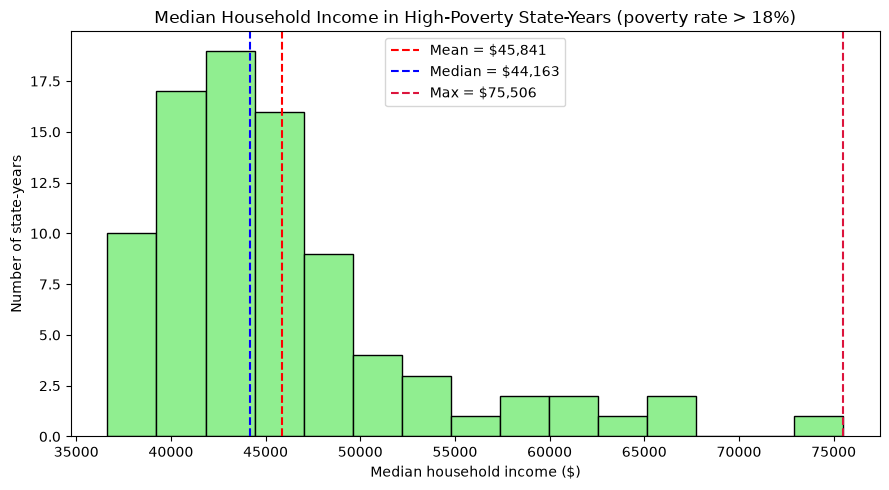

In [9]:
# Managing the data for visualization
inc = low_income.drop_duplicates(["state_abb", "year"])["median_income"]
print(inc.describe())

# Plotting the histogram
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(inc, bins=15, edgecolor="black", color="lightgreen")
ax.axvline(inc.mean(), color="red", linestyle="--", label=f"Mean = ${inc.mean():,.0f}")
ax.axvline(inc.median(), color="blue", linestyle="--", label=f"Median = ${inc.median():,.0f}")
ax.axvline(inc.max(), color="crimson", linestyle="--", label=f"Max = ${inc.max():,.0f}")
ax.set_title("Median Household Income in High-Poverty State-Years (poverty rate > 18%)")
ax.set_xlabel("Median household income ($)")
ax.set_ylabel("Number of state-years")
ax.legend()
plt.tight_layout()
plt.savefig("Visualization I.1.1_ Histogram of median household income in high-poverty state-years.png")
plt.show()

<b> Interpretation of Data </b> <br>
Income in high-poverty state-years is right-skewed. Most values fall between 41,500 and 45,000 dollars, with a mean of about 45841 dollars and a median of 44163 dollars. The long right tail is created by a few state-years with much higher income. The most extreme of them all is 75,506 dollars.<br>
Thus, even among the state-years with a high poverty rate (> 18%), income varies widely.

### Visualization I.1.2: Bar chart of total incidents by crime category in the DMV area

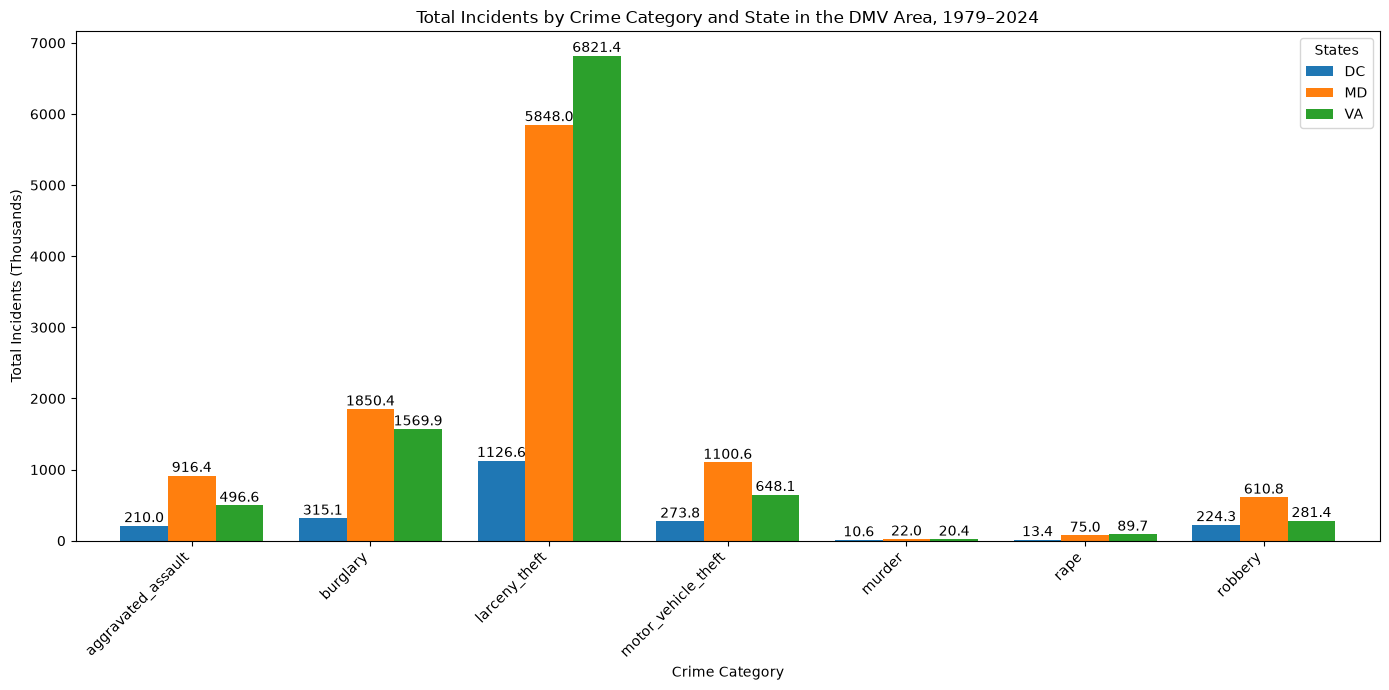

In [10]:
# Managing the data for visualization
dmv_totals = dmv.groupby(["crime_category", "state_abb"])["count"].sum().unstack() / 1000

# PLotting the bar chart
ax = dmv_totals.plot(kind="bar", figsize=(14, 7), width=0.8)
plt.title("Total Incidents by Crime Category and State in the DMV Area, 1979–2024")
plt.xlabel("Crime Category")
plt.ylabel("Total Incidents (Thousands)")
plt.xticks(rotation=45, ha="right")

# Annotate each bar
for container in ax.containers:
    for bar in container:
        v = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            v + 5,
            f"{v:.1f}",
            ha="center",
            va="bottom"
        )
plt.legend(title="States")
plt.tight_layout()
plt.savefig("Visualization I.1.2_ Bar chart of total incidents by crime category in the DMV area.png")
plt.show()

<b>Interpretation of Data </b><br>
In the DMV area, 
- larceny theft accounts for the majority of recorded incidents since 1979.
- Aggravated assault is the most common violent crime, whereas murder is the least committed crime among all the crime categories.
- A lot more crimes have occured in Maryland (MD) and Virginia (VA) than DC.
- Besides larceny theft, there're more records of crimes in Maryland (MD) than VA or DC.

### Visualization I.1.3: Count Plot of the total years each state spent in high-poverty

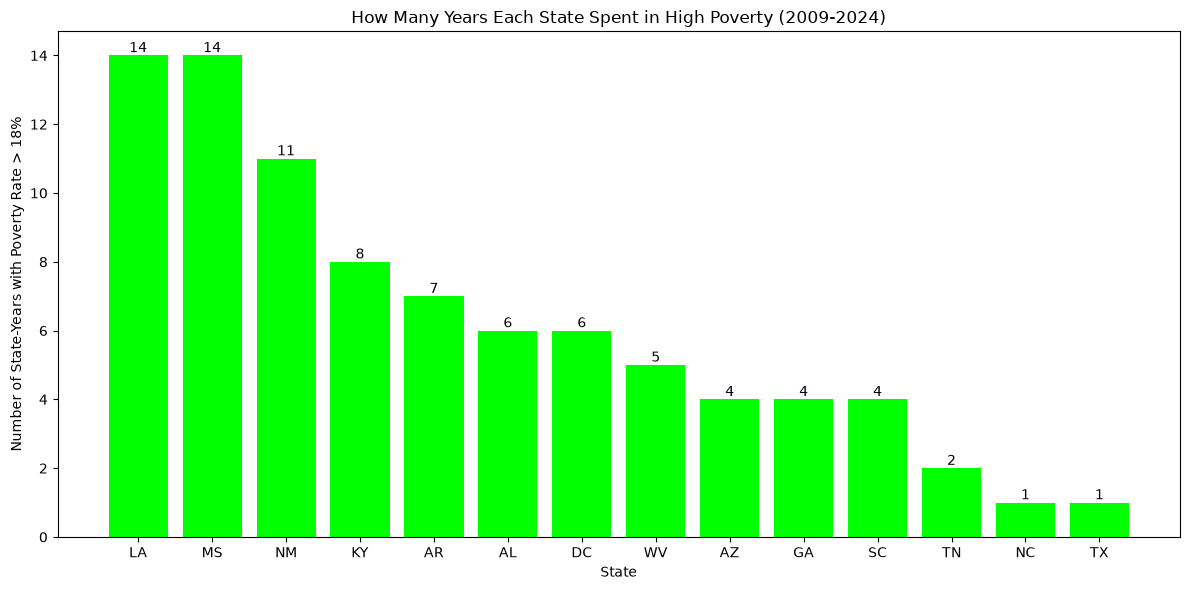

In [11]:
# Managing the data for visualization
state_years = low_income.drop_duplicates(["state_abb", "year"])
counts = state_years["state_abb"].value_counts()

# Plotting the countplot
fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(counts.index, counts.values, color="lime")
for i, v in enumerate(counts):
    ax.text(i, v, int(v), ha="center", va="bottom")
ax.set_title("How Many Years Each State Spent in High Poverty (2009-2024)")
ax.set_xlabel("State")
ax.set_ylabel("Number of State-Years with Poverty Rate > 18%")
plt.tight_layout()
plt.savefig("Visualization I.1.3_ Count Plot of the total years each state spent in high-poverty.png")
plt.show()

<b> Interpretation of Data </b><br>
- Out of 51 states (including DC), only 14 have ever lived in high-poverty from 2009-2024.
- Louisiana and Mississippi have lived in high-poverty for every single year (14 times), which is followed by New Mexico (11), Kentucky (8), and Arkansas (7).
- Several states have only lived in high-poverty for once or twice: North Carolina, Tennessee, Texas.
- The majority of the states that have lived in high-poverty are Southern states of the US.

### Visualization I.2: Line Plot of Crimes in DMV area over time

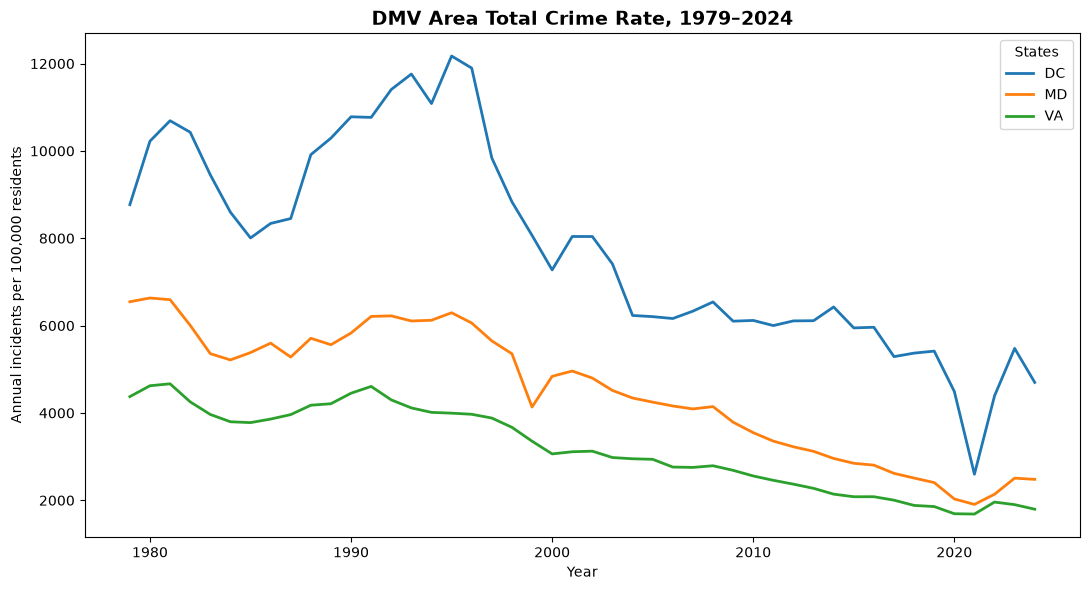

In [12]:
# Annual rate per 100,000 for each crime category (average monthly rate * 12) in the DMV area
dmv_annual = dmv.groupby(["state_abb", "year", "crime_category"])["rate_per_100k_reporting_pop"].mean().unstack() * 12

# Finding the total crime rate
dmv_annual["total_rate"] = dmv_annual[["murder", "rape", "robbery", "aggravated_assault", "burglary", "larceny_theft", "motor_vehicle_theft"]].sum(axis=1)
dmv_annual = dmv_annual.reset_index()

# Plotting the graph
fig, ax = plt.subplots(figsize=(11, 6))
for st, grp in dmv_annual.groupby("state_abb"):
    ax.plot(grp["year"], grp["total_rate"], label=st, linewidth=2)
ax.set_title("DMV Area Total Crime Rate, 1979–2024", fontsize=14, fontweight="bold")
ax.set_xlabel("Year")
ax.set_ylabel("Annual incidents per 100,000 residents")
ax.legend(title="States")
plt.tight_layout()
plt.savefig("Visualization I.2_ Line Plot of Crimes in DMV area over time.png")
plt.show()

<b> Interpretation of Data </b>
- Even though DC had the less crimes than Maryland and Virginia, the crime rate, which takes into consideration the population of the state, of DC is much higher than Maryland and Virginia.
- DC has the highest crime rate in every single year from 1979 - 2024, followed by Maryland, and Virginia.
- In the late 1990s, DC had a huge spike in crime rate, surpassing even the total crime rates of Maryland and Virginia combined.
- Overall, the trend of the crime rates is that it has increased from 1979 to mid 1990s, slowly fallen off from the mid 1990s to 2020, and again started rising from 2021, which could potentially be a consequence of Covid-19.
  

## Section II: Relationship Visualizations

### Visualization II.1: Violent vs Property Crime Rates in High-Poverty State-Years

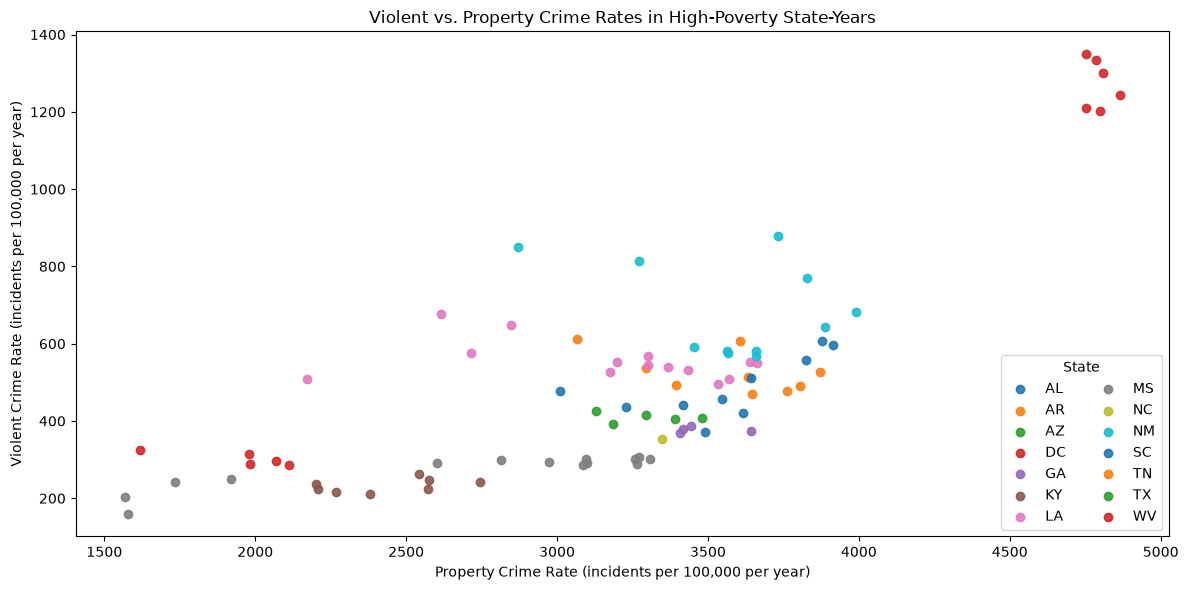

The correlation between the violent and property crime rates is 0.76.


In [13]:
# Annual crime rate per 100,000 for each crime category 
low_income_annual = low_income.groupby(["state_abb", "year", "crime_category"])["rate_per_100k_reporting_pop"].mean().unstack() * 12

# Finding the violent and property crime rates
low_income_annual["violent_rate"] = low_income_annual[["murder", "rape", "robbery", "aggravated_assault"]].sum(axis=1)
low_income_annual["property_rate"] = low_income_annual[["burglary", "larceny_theft", "motor_vehicle_theft"]].sum(axis=1)
low_income_annual = low_income_annual.reset_index()

# Plotting the scatterplot
fig, ax = plt.subplots(figsize=(12, 6))
for st, grp in low_income_annual.groupby("state_abb"):
    ax.scatter(grp["property_rate"], grp["violent_rate"], label=st, alpha=0.9)
ax.set_title("Violent vs. Property Crime Rates in High-Poverty State-Years")
ax.set_xlabel("Property Crime Rate (incidents per 100,000 per year)")
ax.set_ylabel("Violent Crime Rate (incidents per 100,000 per year)")
ax.legend(title="State", loc="lower right", ncol=2)
plt.tight_layout()
plt.savefig("Visualization II.1_ Violent vs Property Crime Rates in High-Poverty State-Years.png")
plt.show()
print(f"The correlation between the violent and property crime rates is {low_income_annual["violent_rate"].corr(low_income_annual["property_rate"]):.2f}.")

<b> Interpretation of Data </b><br>
- The correlation of between the violent and property crime rates is 0.76, which means that they're positively correlated and an increase in violent crime rates will most likely correspond to an increase in property crime rates.
- The outlier (located in the top right) is DC, which has much higher crime and property crime rates than other states.
- New Mexico, Tennessee, South Carolina, and Louisiana have relatively high violent crime for their property crime level.

### Visualization II. 2: Heatmap of correlation between each crime category and each indicator

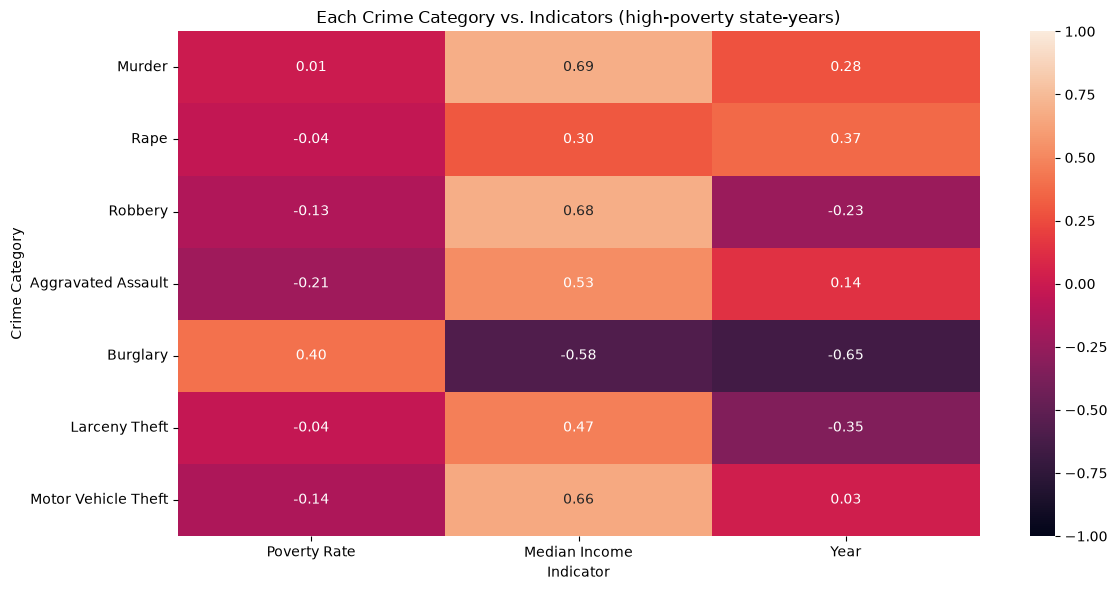

In [14]:
# Cleaning the data for heatmap
crime_categories = ["murder", "rape", "robbery", "aggravated_assault", "burglary", "larceny_theft", "motor_vehicle_theft"]
indices = ["poverty_rate", "median_income", "year"]
state_years = low_income.drop_duplicates(["state_abb", "year"])[["state_abb", "year", "poverty_rate", "median_income"]]
low_income_annual = low_income_annual.drop(columns=["poverty_rate", "median_income"], errors="ignore")
low_income_annual = low_income_annual.merge(state_years, on=["state_abb", "year"])

# Arranging the data for heatmap
cc = low_income_annual[crime_categories + indices].corr().loc[crime_categories, indices]
cc.index = ["Murder", "Rape", "Robbery", "Aggravated Assault", "Burglary", "Larceny Theft", "Motor Vehicle Theft"]
cc.columns = ["Poverty Rate", "Median Income", "Year"]

# Plotting the heatmap
fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(cc, annot=True, fmt=".2f", ax=ax, vmin=-1, vmax=1)
ax.set_title("Each Crime Category vs. Indicators (high-poverty state-years)")
ax.set_xlabel("Indicator")
ax.set_ylabel("Crime Category")
plt.tight_layout()
plt.savefig("Visualization II.2_ Heatmap of correlation between each crime category and each indicator.png")
plt.show()

<b> Interpretation of Data </b><br>
- Burglary is mostly related with economic factors: positive correlated with poverty rate (0.4) and negatively correlated with the median income (-0.58) and the year (-0.65).
- Murder, robbery, aggravated assault, and motor vehicle theft all correlative positively with the median income (0.53-0.69). This is mainly because of DC (an extreme outlier).
- Overally, the high-poverty subset is small, is dominated by a few states, and includes an high extreme outlier (DC). So, these correlations should be understood as descriptive and not as general.

# Summary and Conclusion

## 1) Summary

- <b>Income (histogram):</b> Median income in high-poverty state-years is right-skewed. Most values fall between about 41,500 and 47,800 dollars and a few state-years reach as high as $75,506.
- <b>Crime types (bar chart):</b> Larceny theft is the most common crime category in the DMV area. Aggravated assault is the most common violent crime, and murder is the least common crime overall. Maryland and Virginia have far more total incidents than DC.
- <b>High-poverty states (count plot):</b> Only 14 of the 51 states were ever above 18% poverty between 2009 and 2024. Louisiana and Mississippi were high-poverty in all 14 years of data, and most of the others are Southern states.
- <b>DMV over time (line plot):</b> Despite having far lower incidents than Maryland and Virginia, DC has the highest crime rate in every year from 1979 to 2024, followed by Maryland and then Virginia. Crime rates rose until the mid-1990s, then fell steadily until about 2020. After a dip in 2021, they rose again in 2022 and 2023.
- <b>Violent vs. property crime (scatter plot):</b> The two are strongly and positively correlated (r = 0.76), so state-years with more property crime tend to have more violent crime. However, DC is a clear outlier in the top right.
- <b>Crimes vs. indicators (heatmap):</b> Burglary is the crime most tied to economic factors i.e. it is positively related to poverty (0.40), negatively related to income (-0.58), and has declined over time (-0.65). Murder, robbery, aggravated assault and motor vehicle theft are positively related to median income (0.53 to 0.69), mostly because of DC. Poverty rate has little to no link with any of the crime categories besides burglary.

## 2) Conclusion

Across the filtered datasets, property crimes have been committed way more than violent crimes. In every single comparison, DC has stood out as an outlier: it's crime rate is much higher in Maryland's and Virginia's, despite having a lower number of crime records, and it is also the main reason why income appears to be positively correlated to several crimes (except burglary). Crime rates in the DMV area have been on a decline since the mid-1990s. Economic indicators explain little overall. Poverty isn't strongly correlated to most of the crimes, and only burglary shows a clear economic pattern.